In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080210  # 改成数字，不要加引号

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp01
[学号] 20244080210
[机器指纹] 90cf8d31534ddeec
[RUN_ID] 20244080210-90cf8d31534ddeec


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 围绕半圆定律

### 1. 编写 wigner_density(x)

In [3]:
def wigner_density(x):
    # 使用 np.where 来应对数组操作（如果传入的是标量也能正常工作）
    return np.where(np.abs(x) <= 2, (1 / (2 * np.pi)) * np.sqrt(4 - x**2), 0.0)

# 测试
print(wigner_density(1.0)) # 应该输出约 0.275

0.27566444771089604


### 2. 编写 generate_wigner(n)

In [4]:
def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError("n 必须是正整数")
    # 生成标准正态分布矩阵，并缩放至方差 1/n
    Z = np.random.randn(n, n) / np.sqrt(n)
    # 构造对称矩阵（保留上三角，下三角由转置得到）
    Z_sym = np.triu(Z) + np.triu(Z, 1).T
    return Z_sym

### 3. 编写 get_spectrum(matrix)

In [5]:
def get_spectrum(matrix):
    # 因为是实对称矩阵，用 eigvalsh 计算特征值更快且必定返回实数
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)

### 4. 画图并说明

n_values = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(8, 16))

x_range = np.linspace(-2.5, 2.5, 500)
y_density = wigner_density(x_range)

for ax, n in zip(axes, n_values):
    W = generate_wigner(n)
    eigvals = get_spectrum(W)
    
    # 绘制标准化直方图（density=True 表示面积为1）和半圆曲线
    ax.hist(eigvals, bins=50, density=True, color='blue', alpha=0.7, label='特征值分布')
    ax.plot(x_range, y_density, color='red', linewidth=2, label='半圆密度')
    
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.5, 2.5)
    ax.legend()

plt.tight_layout()
plt.show()

从图中可以看出，当 n = 100 时，特征值分布的边缘已经有收敛趋势，但仍有明显波动；当 n 大约达到 500 甚至 1000 时，直方图与红色的半圆密度曲线拟合得非常好。

# Conway 的生命游戏

### 1. 编写 is_valid_board(board)

In [6]:
def is_valid_board(board):
    # 必须是二维数组，且所有元素只能是 0 或 1
    return isinstance(board, np.ndarray) and board.ndim == 2 and np.all(np.isin(board, [0, 1]))

### 2. 编写 gol_step(board)

In [7]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入必须是一个有效的生命游戏棋盘（二维 ndarray，元素为 0 或 1）")
    
    # 使用 np.roll 实现环绕边界的邻居计数
    neighbors = np.zeros_like(board)
    for i in [-1, 0, 1]:
        for j in [-1, 0, 1]:
            if i == 0 and j == 0:
                continue
            neighbors += np.roll(np.roll(board, i, axis=0), j, axis=1)
            
    # 规则应用
    new_board = np.zeros_like(board)
    # 活细胞存活：有 2 或 3 个活邻居
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    # 死细胞复活：恰好 3 个活邻居
    new_board[(board == 0) & (neighbors == 3)] = 1
    
    return new_board

### 3. 编写 draw_gol_board(board)

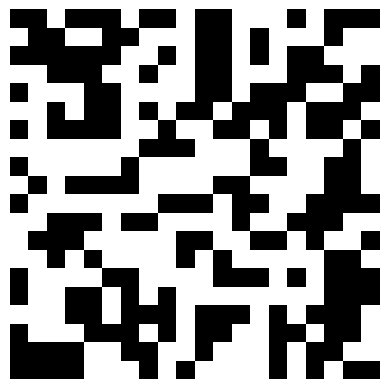

In [8]:
def draw_gol_board(board):
    plt.imshow(board, cmap='binary', interpolation='nearest')
    plt.xticks([]) # 隐藏 x 轴刻度
    plt.yticks([]) # 隐藏 y 轴刻度
    plt.axis('off') # 关闭坐标轴
    plt.show()
    
# 简单测试一下（你可以自己随便造一个棋盘跑一下）
test_board = np.random.choice([0, 1], size=(20, 20))
draw_gol_board(test_board)

# 使用 pandas DataFrame

### 1. 读取数据并回答

In [9]:
import pandas as pd

# 1. 读取数据
df = pd.read_csv('iris.csv')

# 2. 删掉无用的索引列 'Unnamed: 0'
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# 3. 把长长的列名改短，方便后面计算（这样就不会因为列名带空格和(cm)报错了）
df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

# 4. 补上缺失的“物种”列（前50个setosa，中间50个versicolor，后50个virginica）
df['species'] = ['setosa'] * 50 + ['versicolor'] * 50 + ['virginica'] * 50

# --- 回答问题 ---
print("数据点个数:", df.shape[0])
print("\n列名及数据类型:\n", df.dtypes)
print("\n花卉种类:", df['species'].unique())

数据点个数: 150

列名及数据类型:
 sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

花卉种类: <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str


### 2. 修改错误数据

In [10]:
# 根据作业要求，修改第 35 行（索引 34）和第 38 行（索引 37）
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print("修改后的第 34 行:\n", df.loc[34])
print("\n修改后的第 37 行:\n", df.loc[37])

修改后的第 34 行:
 sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

修改后的第 37 行:
 sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object


### 3.添加新特征

In [11]:
# 添加 Petal.Ratio 和 Sepal.Ratio 列
df['Petal.Ratio'] = df['petal_length'] / df['petal_width']
df['Sepal.Ratio'] = df['sepal_length'] / df['sepal_width']

print("添加新特征后的前 3 行:")
print(df[['Petal.Ratio', 'Sepal.Ratio']].head(3))

添加新特征后的前 3 行:
   Petal.Ratio  Sepal.Ratio
0          7.0     1.457143
1          7.0     1.633333
2          6.5     1.468750


### 4.保存文件

In [12]:
# 保存为 iris_corrected.csv，index=False 表示不保存行号
df.to_csv('iris_corrected.csv', index=False)
print("文件已成功保存为 iris_corrected.csv！")

文件已成功保存为 iris_corrected.csv！


### 5.按花卉种类分组计算

In [13]:
# 按 'species' 分组，对两个比例列进行多种统计计算
grouped_stats = df.groupby('species')[['Petal.Ratio', 'Sepal.Ratio']].agg(
    ['mean', 'median', 'min', 'max', 'std']
)

print("分组统计结果:\n")
print(grouped_stats)

分组统计结果:

           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.471380   
versicolor    3.182408  3.230769  0.335714   4.1  0.515861    2.165531   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.466667  1.268293  1.956522  0.119677  
versicolor  2.161290  1.764706  2.818182  0.228104  
virginica   2.169540  1.823529  2.961538  0.246992  
